In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

sns.set_theme(style="whitegrid")

log_dir = "logs/"
feat_file = max(glob.glob(f"{log_dir}latency_features_*.csv"), key=os.path.getctime)
ml_file = max(glob.glob(f"{log_dir}latency_ml_*.csv"), key=os.path.getctime)
fb_file = max(glob.glob(f"{log_dir}latency_feedback_*.csv"), key=os.path.getctime)

df_feat = pd.read_csv(feat_file)
df_ml = pd.read_csv(ml_file)
df_fb = pd.read_csv(fb_file)

print(f"Loaded Features: {feat_file}")
print(f"Loaded ML: {ml_file}")
print(f"Loaded Feedback: {fb_file}")

Loaded Features: logs\latency_features_20261025_234023.csv
Loaded ML: logs\latency_ml_20261025_234432.csv
Loaded Feedback: logs\latency_feedback_20261025_234024.csv


In [7]:
# PyGame redraws at 20Hz and logs duplicate timestamps if no new prediction arrived.
# We keep only the 'first' instance a prediction hits the screen.
df_fb_unique = df_fb.drop_duplicates(subset=['Timestamp'], keep='first')

# Inner join to only analyze frames that made it all the way to the screen
df = df_feat.merge(df_ml, on="Timestamp")
df = df.merge(df_fb_unique, on="Timestamp")

# Convert LSL Timestamp to relative seconds from the start of the experiment
df['Time_s'] = df['Timestamp'] - df['Timestamp'].iloc[0]

components = [
    'Acquisition_ms', 
    'Preprocessing_ms', 
    'Feature_ms', 
    'Latency_ms',          # ML inference latency
    'Feedback_Update_ms', 
    'Total_End_to_End_ms'
]

df.head()

,Timestamp,Acquisition_ms,Preprocessing_ms,Feature_ms,Latency_ms,Feedback_Update_ms,Total_End_to_End_ms,Time_s
0,19264.577959,0.2673,0.1152,1.4442,1.0612,0.4574,20.0446,0.000000
1,19264.690230,0.3516,0.0974,1.4673,0.8043,0.4792,8.4964,0.112271
2,19264.803259,0.3379,0.1207,1.3990,0.8968,0.5176,48.7084,0.225300
3,19264.916206,0.4112,0.1301,2.3882,1.2012,0.5817,37.8145,0.338247
4,19265.037184,0.3345,0.1391,1.6997,0.9901,0.6546,18.4399,0.459225


In [8]:
print("--- Basic Descriptive Statistics ---")
display(df[components].describe().round(2))

print("\n--- Tail Latency (95th and 99th Percentile) ---")
display(df[components].quantile([0.95, 0.99]).round(2))

print("\n--- Component Breakdown (%) ---")
mean_latencies = df[components].mean()
breakdown = (mean_latencies[:-1] / mean_latencies[:-1].sum()) * 100
display(breakdown.round(1))

--- Basic Descriptive Statistics ---


,Acquisition_ms,Preprocessing_ms,Feature_ms,Latency_ms,Feedback_Update_ms,Total_End_to_End_ms
count,2166.00,2166.00,2166.00,2166.00,2166.00,2166.00
mean,0.34,0.11,1.59,0.87,0.52,29.51
std,0.08,0.03,0.31,0.19,0.30,14.89
min,0.11,0.04,0.84,0.48,0.22,3.27
25%,0.29,0.09,1.43,0.78,0.44,16.64
50%,0.35,0.11,1.49,0.82,0.47,29.43
75%,0.39,0.12,1.71,0.93,0.54,41.87
max,1.59,0.59,4.55,1.91,12.83,105.31



--- Tail Latency (95th and 99th Percentile) ---


,Acquisition_ms,Preprocessing_ms,Feature_ms,Latency_ms,Feedback_Update_ms,Total_End_to_End_ms
0.95,0.44,0.15,2.19,1.23,0.73,52.27
0.99,0.60,0.22,2.62,1.49,1.04,54.93



--- Component Breakdown (%) ---


Acquisition_ms        10.0
Preprocessing_ms       3.2
Feature_ms            46.4
Latency_ms            25.3
Feedback_Update_ms    15.0
dtype: float64

In [9]:
total_features_generated = len(df_feat)
total_frames_rendered = len(df)
dropped_frames = total_features_generated - total_frames_rendered
drop_rate = (dropped_frames / total_features_generated) * 100

print(f"Total feature windows generated: {total_features_generated}")
print(f"Total feedback frames rendered: {total_frames_rendered}")
print(f"Dropped Frames: {dropped_frames} ({drop_rate:.2f}%)\n")

# Jitter is the variance in time between consecutive screen updates
df['Jitter_ms'] = df['Timestamp'].diff() * 1000
mean_jitter = df['Jitter_ms'].mean()
std_jitter = df['Jitter_ms'].std()

print("--- Inter-frame Jitter ---")
print(f"Mean time between frames: {mean_jitter:.2f} ms")
print(f"Jitter standard deviation: {std_jitter:.2f} ms")

Total feature windows generated: 2170
Total feedback frames rendered: 2166
Dropped Frames: 4 (0.18%)

--- Inter-frame Jitter ---
Mean time between frames: 113.84 ms
Jitter standard deviation: 10.00 ms


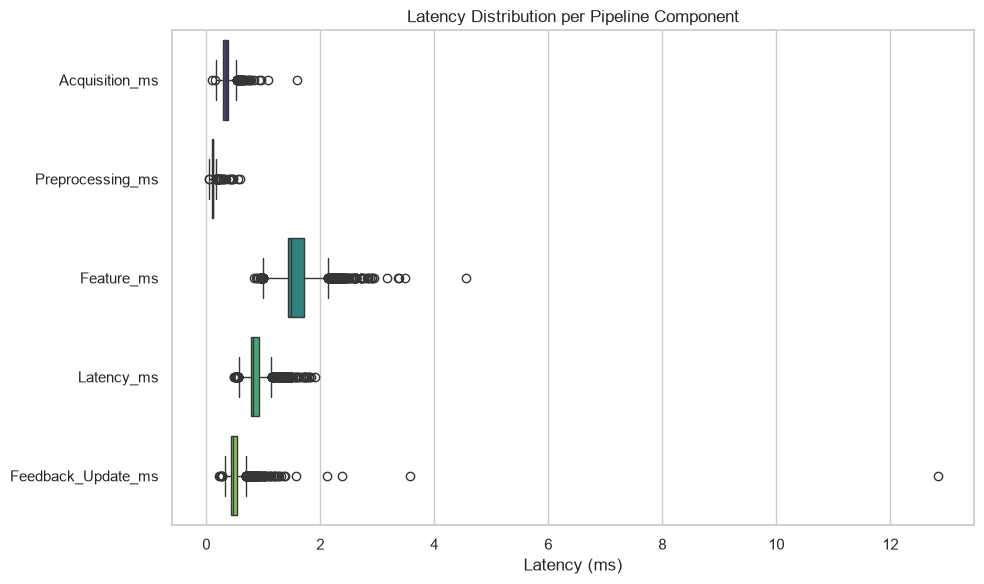

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[components[:-1]], orient="h", palette="viridis")
plt.title("Latency Distribution per Pipeline Component")
plt.xlabel("Latency (ms)")
plt.tight_layout()
plt.show()

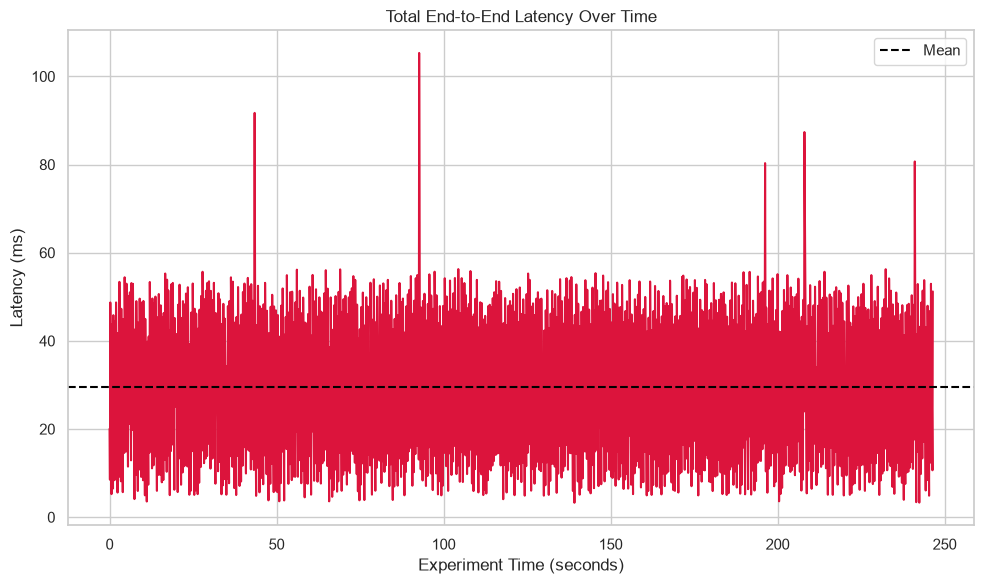

In [12]:
plt.figure(figsize=(10, 6))
sns.lineplot(x='Time_s', y='Total_End_to_End_ms', data=df, color="crimson", linewidth=1.5)
plt.title("Total End-to-End Latency Over Time")
plt.xlabel("Experiment Time (seconds)")
plt.ylabel("Latency (ms)")
plt.axhline(df['Total_End_to_End_ms'].mean(), color='black', linestyle='--', label="Mean")
plt.legend()
plt.tight_layout()
plt.show()

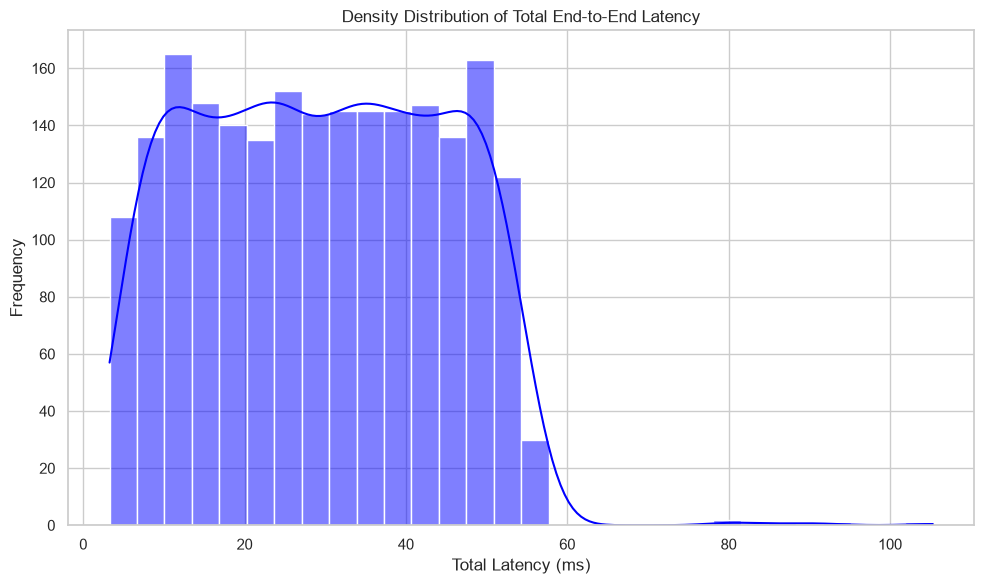

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Total_End_to_End_ms'], kde=True, color="blue", bins=30)
plt.title("Density Distribution of Total End-to-End Latency")
plt.xlabel("Total Latency (ms)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()